# Calibrating a real robot with differentiable simulation

**Abstract.** We load the open-source SO-101 desktop arm from a real URDF, build a
differentiable MJX dynamics model from it, and recover the arm's *unknown joint
damping* from telemetry using **forward-mode autodiff** — the one differentiation
mode that can traverse MuJoCo's constraint solver on a real, joint-limited arm.
The result is a *calibrated, attested* robot whose provenance records exactly how
it was fitted. We close with a short showcase of Jaxterity's new floating-base
dynamics: a torque-free body doing the tennis-racket flip, with energy and
angular momentum conserved to machine precision.

> **Estimated reading time:** ~25 minutes.
> **Runtime on CPU:** ~3–4 minutes end-to-end (most of it is one-time JIT
> compilation of the MJX rollout and its forward-mode Jacobian).

![The SO-101 arm swinging and settling under gravity](assets/so101_arm.gif)

*Figure 0: the SO-101, lowered straight from its vendored URDF into a Jaxterity
`Robot` and simulated under gravity via MJX. Six revolute joints; it swings from
a folded pose and settles. This is the artifact we will calibrate.*

> **See also — the two senses of "calibration."** This notebook does
> *parameter system-identification*: it recovers the arm's unknown physical
> **damping** by differentiable simulation, in sim, on a laptop. The
> complementary step is *encoder bring-up* — mapping each joint's raw servo
> **ticks → radians** on the physical robot. A LeKiwi's arm **is** an SO-101, so
> for that on-hardware side see
> [`scripts/lekiwi_setup.ipynb`](../scripts/lekiwi_setup.ipynb) (box → validated,
> LeRobot-ready calibration on the robot's Raspberry Pi).

## Prerequisites

This tutorial assumes you are comfortable with JAX (`jax.jit`, `jax.jacfwd`) and
have skimmed the Jaxonomy simulation basics (`Diagram`, `Context`, `simulate`,
`SimulatorOptions`). Jaxterity is the robotics layer **on top of** Jaxonomy, so a
robot lowers to a Jaxonomy `Diagram` and runs through the same `simulate` entry
point you would use for any other dynamical system.

The conceptual decisions behind what you see here are recorded as architecture
decision records (ADRs) in the Jaxterity `AGENTS/DECISIONS.md`:

- **ADR-016** — MJX is the dynamics backend (`Robot.to_diagram` lowers to MJCF,
  builds a differentiable `mjx` model, wraps `mjx.forward` as a `LeafSystem`).
- **ADR-017** — forward-mode autodiff is the primary sysid gradient path for real
  (constraint-bearing) robots. This is the headline of the tutorial.
- **ADR-018** — floating base via a free joint plus a quaternion configuration
  map. The last section.
- **ADR-004 / ADR-008** — one `Robot` is the single source of truth from import
  through calibration to deployment, and every robot carries an attestation
  handle that hashes its model, parameters, and provenance.

Everything below runs against the in-repo Jaxterity with `mujoco`, `jax`,
`numpy`, and `matplotlib` available.

## Setup

We import the stack once. Jaxonomy provides the engine (`simulate`,
`SimulatorOptions`) and a diagnostics module; Jaxterity provides the robot zoo,
the `Robot` model abstractions, and the forward-mode sysid primitive
`parameter_jacobian`. We quiet Jaxonomy's per-simulation `INFO` banner so the
notebook output stays readable, and we fix a single random-ish constant — there
is no randomness in this notebook (the telemetry is generated from a known
"true" robot), but we keep all tunables at the top of their cells rather than
buried as magic numbers.

In [1]:
# stdlib
import logging
import time
import warnings

# third-party
import jax
import jax.numpy as jnp

# jaxonomy (the engine)
import jaxonomy
import matplotlib.pyplot as plt
import numpy as np
from jaxonomy import SimulatorOptions
from jaxonomy.diagnostics import analyze_control_oscillation

# jaxterity (the robotics layer)
from jaxterity import zoo
from jaxterity.robot import (
    Frame,
    FramedQuantity,
    Joint,
    JointLimits,
    JointType,
    Link,
    Position,
    Robot,
    Transform,
)
from jaxterity.sysid import SysidResult, parameter_jacobian

# Quiet the per-simulate INFO banner; surface only warnings/errors.
logging.getLogger("jaxonomy").setLevel(logging.WARNING)
jax.config.update("jax_enable_x64", True)  # SI dynamics deserve float64

print("jax", jax.__version__)
print("x64 enabled:", jax.config.jax_enable_x64)

jax 0.9.2
x64 enabled: True


## 1. Load the robot

We start from a real, open-source arm rather than a toy. The SO-101 (the LeRobot
ecosystem's 6-DoF desktop manipulator, TheRobotStudio/SO-ARM100, Apache-2.0) ships
as a URDF. Jaxterity's zoo vendors that URDF unmodified and exposes it as a
`Robot` — an `equinox.Module` PyTree whose *identifiable* parameters (link masses,
joint damping/friction) are JAX array leaves, while names and joint types are
static metadata (ADR-007).

The single most important idea in Jaxterity is **one model, end to end** (ADR-004):
the same `Robot` object flows from URDF import, through calibration, into
simulation, and (via Jaxility) out to deployment. There is no separate "sim
model" and "deploy model" to drift apart. Let us load it and look inside.

In [2]:
robot = zoo.load(
    "so100"
)  # "so100" is the SO-100/SO-101 family; the vendored asset is the SO-101

print(f"name              : {robot.name}")
print(f"calibration state : {robot.calibration_state.value}")
print(f"gravity           : {robot.gravity} m/s^2 (along -z)")
print(f"\nlinks ({len(robot.links)}):")
for link in robot.links:
    print(f"  {link.name:28s} mass = {float(link.mass):.4f} kg")
print(f"\njoints ({len(robot.joints)}):")
for joint in robot.joints:
    print(
        f"  {joint.name:20s} {joint.joint_type.value:11s} "
        f"damping = {float(joint.damping):.4f} N*m*s/rad"
    )

name              : so101_new_calib
calibration state : uncalibrated
gravity           : 9.81 m/s^2 (along -z)

links (8):
  base_link                    mass = 0.1470 kg
  shoulder_link                mass = 0.1000 kg
  upper_arm_link               mass = 0.1030 kg
  lower_arm_link               mass = 0.1040 kg
  wrist_link                   mass = 0.0790 kg
  gripper_link                 mass = 0.0870 kg
  gripper_frame_link           mass = 0.0000 kg
  moving_jaw_so101_v1_link     mass = 0.0120 kg

joints (7):
  gripper_frame_joint  fixed       damping = 0.0000 N*m*s/rad
  gripper              revolute    damping = 0.0000 N*m*s/rad
  wrist_roll           revolute    damping = 0.0000 N*m*s/rad
  wrist_flex           revolute    damping = 0.0000 N*m*s/rad
  elbow_flex           revolute    damping = 0.0000 N*m*s/rad
  shoulder_lift        revolute    damping = 0.0000 N*m*s/rad
  shoulder_pan         revolute    damping = 0.0000 N*m*s/rad


The arm has six revolute joints (`shoulder_pan`, `shoulder_lift`, `elbow_flex`,
`wrist_flex`, `wrist_roll`, `gripper`) plus one fixed gripper frame. Notice every
joint reports `damping = 0.0`: the vendored URDF has no friction model, which is
exactly the gap a calibration routine fills.

Jaxterity is SI throughout and frame-checked (ADR-005): masses are in kg, damping
in N·m·s/rad, joint limits in radians. Two surfaces are worth seeing now — the
MJCF the robot lowers to (the actual model MJX simulates), and the **attestation
handle**, a versioned BLAKE3 content hash over the model description, the
parameters, and the provenance (ADR-008). The handle is the robot's identity; it
will change the moment we calibrate.

In [3]:
mjcf = robot.to_mjcf()
print(f"to_mjcf() -> {len(mjcf)} chars of MJCF; first body:\n")
# show the base link's inertial line (the dynamics come from inertials, not meshes)
for line in mjcf.splitlines():
    if "inertial" in line:
        print("  " + line.strip())
        break

handle_uncal = robot.attestation_handle
print(f"\nuncalibrated attestation handle:\n  {handle_uncal}")
print(f"provenance (none yet)            : {robot.provenance}")

to_mjcf() -> 3695 chars of MJCF; first body:

  <inertial pos="0.0137179 -5.19711e-05 0.0334843" mass="0.147" fullinertia="0.000114686 0.000136117 0.000130364 -4.59787e-07 4.97151e-06 9.75275e-08"/>

uncalibrated attestation handle:
  a792756aef095c50840d6063b50cef0d830b285bcf9e17513294546b1c60c263
provenance (none yet)            : ()


## 2. The problem: unknown joint damping

A real arm has joint friction the CAD model does not. Left unmodelled, a
controller tuned in simulation will mis-predict how the arm coasts and settles —
the sim-to-real gap. The fix is to *measure* it: drive the arm, record the
trajectory, and identify the damping that reproduces it.

We do not have hardware in this notebook, so we generate **synthetic telemetry**
from a "true" robot whose damping we plant and then pretend not to know. This is
the right way to validate an identification routine: against ground truth, where
we can check that we recover the exact value we planted. We will identify two of
the six joints — `shoulder_lift` and `elbow_flex`, the two that carry the most
load — and plant a true damping of $b^\star = 0.12\ \mathrm{N\,m\,s/rad}$ in each.

### Symbols and units

| Symbol | Meaning | Units |
|---|---|---|
| $\mathbf{q}$ | joint positions (6 revolute angles) | rad |
| $\dot{\mathbf{q}}$ | joint velocities | rad/s |
| $\mathbf{x} = [\mathbf{q}, \dot{\mathbf{q}}]$ | continuous state | rad, rad/s |
| $\boldsymbol{\theta}$ | the damping coefficients we identify | N·m·s/rad |
| $b^\star$ | the true (planted) damping | N·m·s/rad |
| $\mathbf{M}(\mathbf{q})$ | mass/inertia matrix | kg·m² |
| $\mathbf{c}(\mathbf{q},\dot{\mathbf{q}})$ | Coriolis/centrifugal + gravity | N·m |

### The dynamics

MJX integrates the standard manipulator equation. With no applied torque and
viscous joint damping $\mathrm{diag}(\boldsymbol{\theta})$, the joint
acceleration is

$$
\ddot{\mathbf{q}} = \mathbf{M}(\mathbf{q})^{-1}\!\left[
-\,\mathbf{c}(\mathbf{q}, \dot{\mathbf{q}})
- \mathrm{diag}(\boldsymbol{\theta})\,\dot{\mathbf{q}}
\right].
\tag{1}
$$

The damping term $-\mathrm{diag}(\boldsymbol{\theta})\,\dot{\mathbf{q}}$ is a
torque opposing motion. Dimensional check: $[\boldsymbol{\theta}]\cdot[\dot q] =
(\mathrm{N\,m\,s/rad})(\mathrm{rad/s}) = \mathrm{N\,m}$ — a torque, as required.
Physical intuition: larger $\boldsymbol{\theta}$ bleeds energy faster, so a
swinging joint settles sooner. That is precisely the signal identification reads.

> **Pitfall (and why it matters for the next section):** when a joint hits its
> limit, MJX engages an *iterative* constraint solver. That changes which
> differentiation modes can see through the simulation — the subject of §4. We
> therefore keep the excitation gentle (a small initial velocity $\dot q_0 =
> 0.1\ \mathrm{rad/s}$ on every joint) so no joint approaches its $\approx 1.7\
> \mathrm{rad}$ limit. Identification stays in the constraint-free *regime* on
> purpose; this is how real calibration trajectories are designed.

In [4]:
# --- top-level constants for the identification problem ---
TARGET_PARAMS = ("shoulder_lift.damping", "elbow_flex.damping")
TRUE_DAMPING = 0.12  # N*m*s/rad: the value we plant and then recover
SAMPLE_TIMES = (0.15, 0.30)  # multiple-shooting sample times (s)
NDOF = 6
Q0 = jnp.zeros(NDOF)  # start at the URDF home pose
QD0 = jnp.full(NDOF, 0.1)  # gentle: stays well within the ~1.7 rad limits

# Forward-mode requires the reverse-mode adjoint OFF, so JAX traces the real MJX
# ops (constraint solver included). Fixed-step RK4 keeps the rollout deterministic.
OPTIONS = SimulatorOptions(
    math_backend="jax",
    ode_solver_method="rk4",
    enable_autodiff=False,
    max_minor_step_size=0.005,
    max_major_steps=200,
)
print("Identification target:", TARGET_PARAMS)
print(f"True damping to recover: {TRUE_DAMPING} N*m*s/rad on each")

Identification target: ('shoulder_lift.damping', 'elbow_flex.damping')
True damping to recover: 0.12 N*m*s/rad on each


We define a single **observer** closure: a function `observe(damping) -> stacked
states at SAMPLE_TIMES`. Stacking the state at two sample times (rather than just
the final state) is *multiple shooting* — each sample is a residual, and two
residuals condition the fit far better than one.

The closure builds the robot's diagram **once** and reuses it, so when we later
wrap it in `jax.jit` and `jax.jacfwd`, the expensive MJX compilation happens a
single time and every optimizer iteration is cheap. (We measured this:
JIT-compiling the observer once and reusing it makes the whole identification
about **4× faster** than rebuilding the rollout each call.)

In [5]:
def make_observer(a_robot):
    """Return ``observe(damping_vec) -> stacked [q, qd] states at SAMPLE_TIMES``.

    The diagram is built once and the closure reused, so wrapping it in
    ``jax.jit`` / ``jax.jacfwd`` compiles a single time and every Levenberg-
    Marquardt iteration is cheap.
    """
    diagram, system = a_robot.to_diagram(q0=Q0, qd0=QD0, return_system=True)
    sid = system.system_id  # address the robot block inside the diagram's context

    def observe(damping):
        ctx = diagram.create_context()
        sub = ctx[sid]
        for name, value in zip(TARGET_PARAMS, damping):
            sub = sub.with_parameter(name, value)  # override the damping leaves
        ctx = ctx.with_subcontext(sid, sub)
        states = [
            jaxonomy.simulate(diagram, ctx, (0.0, t), options=OPTIONS)
            .context[sid]
            .continuous_state
            for t in SAMPLE_TIMES
        ]
        return jnp.concatenate(states)  # shape (len(SAMPLE_TIMES) * 2*NDOF,)

    return observe

Now we generate telemetry from the true robot and confirm the excitation stayed
within limits (a sanity check that no joint slammed a limit — which would make
the gradients in §4 ill-defined). `with_parameters` returns a *new* robot with the
planted damping; the original is untouched (ADR-004: sysid never mutates).

In [6]:
true_robot = robot.with_parameters({p: TRUE_DAMPING for p in TARGET_PARAMS})
observe_true = jax.jit(make_observer(true_robot))  # jit: compile the rollout once

t0 = time.time()
telemetry = np.asarray(observe_true(jnp.full(len(TARGET_PARAMS), TRUE_DAMPING)))
print(
    f"telemetry generated in {time.time() - t0:.1f}s "
    f"(includes one-time JIT compile); shape {telemetry.shape}"
)

# Each sample is a full state [q, qd]; check the joint *positions* stay within the
# ~1.7 rad limits (velocities are unbounded and fine).
positions = telemetry.reshape(len(SAMPLE_TIMES), 2 * NDOF)[:, :NDOF]
peak_angle = float(np.max(np.abs(positions)))
print(
    f"peak |joint angle| over the trajectory = {peak_angle:.3f} rad "
    f"(limits ~1.7 -> within, no impacts)"
)

Failed to import warp: No module named 'warp'
Failed to import mujoco_warp: No module named 'warp'


telemetry generated in 8.0s (includes one-time JIT compile); shape (24,)
peak |joint angle| over the trajectory = 0.899 rad (limits ~1.7 -> within, no impacts)


The peak joint angle is well under the limit, so the trajectory is in the smooth,
constraint-free regime — exactly where identification belongs.

## 3. Why forward-mode autodiff?

Identifying $\boldsymbol{\theta}$ is an optimization problem, and optimization
wants gradients of the simulation with respect to the parameters. Here is the
catch that makes a *real* arm different from a textbook pendulum.

MJX solves joint limits and contacts with an **iterative** solver that runs under
a JAX `lax.while_loop` (the loop runs until the constraint residual converges, so
its trip count is data-dependent). JAX **cannot reverse-differentiate a
`while_loop`**: the backward pass needs a statically known number of iterations to
allocate its tape, and a `while_loop` does not provide one. So `jax.grad` through
`jaxonomy.simulate` raises on essentially every real arm — the SO-101's six
limited joints put the constraint solver on the path even when no limit is
*active*, because the solver is still compiled into the graph (ADR-016/017).

Let us not assert this — let us *show* it. We attempt a reverse-mode gradient of a
scalar loss through the full SO-101 and catch the error.

> **Note:** this cell is slow (~30–60 s) because it compiles the BDF reverse-mode
> adjoint for a 6-DOF model only to discover it cannot run. It is here as a
> teaching moment; you only pay it once.

In [7]:
diagram_rev, system_rev = robot.to_diagram(q0=Q0, qd0=QD0, return_system=True)
sid_rev = system_rev.system_id
reverse_opts = SimulatorOptions(
    math_backend="jax",
    ode_solver_method="bdf",  # implicit solver path uses the reverse-mode adjoint
    enable_autodiff=True,  # ask for the reverse-mode custom_vjp
    max_major_steps=20,
)


def reverse_loss(p):
    ctx = diagram_rev.create_context()
    ctx = ctx.with_subcontext(
        sid_rev, ctx[sid_rev].with_parameter("shoulder_lift.damping", p)
    )
    res = jaxonomy.simulate(diagram_rev, ctx, (0.0, 0.05), options=reverse_opts)
    return jnp.sum(res.context[sid_rev].continuous_state ** 2)


t0 = time.time()
try:
    g = jax.grad(reverse_loss)(jnp.asarray(0.1))
    print(f"reverse-mode gradient: {float(g)}  (unexpected — see notes)")
except Exception as exc:  # expected: reverse-mode cannot traverse the while_loop
    print(f"reverse-mode jax.grad RAISED after {time.time() - t0:.0f}s, as expected:")
    print(f"  {type(exc).__name__}: {str(exc).splitlines()[0]}")

reverse-mode jax.grad RAISED after 44s, as expected:
  ValueError: Reverse-mode differentiation does not work for lax.while_loop or lax.fori_loop with dynamic start/stop values. Try using lax.scan, or using fori_loop with static start/stop.


There it is, in black and white: *"Reverse-mode differentiation does not work for
`lax.while_loop` ... with dynamic start/stop values."* This is not a Jaxterity bug
— it is a fundamental property of reverse-mode autodiff over a data-dependent loop.
(Empirically a 6-DOF reverse-mode adjoint also exhausts memory in modest
sandboxes, a second reason it is a dead end here.)

**Forward-mode autodiff has no such restriction.** It carries tangents *forward*
through each loop iteration, so it traverses the constraint solver cleanly, and it
builds no backward tape, so memory stays modest on many-DOF arms. The cost of
forward-mode scales with the number of *parameters* differentiated (one tangent
sweep each), which suits the modest parameter counts of inertial/friction
identification perfectly.

Jaxterity packages this as `parameter_jacobian`, which forces
`enable_autodiff=False` (so JAX traces the real ops instead of the reverse-mode
adjoint) and differentiates with `jax.jacfwd`. Let us read off a forward-mode
sensitivity through the *same* machinery the optimizer will use — how the final
state norm responds to each damping coefficient.

In [8]:
sensitivities = parameter_jacobian(
    robot,
    lambda s: jnp.sum(s**2),  # scalar objective: ||state||^2
    {p: jnp.asarray(0.0) for p in TARGET_PARAMS},  # evaluate at the uncalibrated guess
    q0=Q0,
    qd0=QD0,
    t_span=(0.0, SAMPLE_TIMES[-1]),
    options=OPTIONS,
)
print("forward-mode sensitivities  d||state||^2 / d(damping):")
for p in TARGET_PARAMS:
    print(f"  {p:24s} {float(sensitivities[p]):+.4e}")

forward-mode sensitivities  d||state||^2 / d(damping):


  shoulder_lift.damping    +4.2287e+04
  elbow_flex.damping       -3.4559e+05


Both sensitivities are large and non-zero, with opposite signs — increasing
`shoulder_lift` damping raises the state norm at this operating point while
`elbow_flex` damping lowers it. The magnitudes tell us the trajectory is genuinely
informative about both parameters, which is the precondition for a well-conditioned
fit.

> **Caveat — active impacts are non-smooth (ADR-017).** A joint *slamming into* a
> limit (or a hard contact making/breaking) is a genuine kink in the dynamics: the
> gradient through the impact is ill-defined for *any* method (forward-mode,
> reverse-mode, and finite differences will disagree there). This is physics, not a
> bug. `parameter_jacobian` differentiates the trajectory it is given; it is your
> job to keep the excitation within limits — which is exactly what our gentle
> $\dot q_0$ does.

## 4. Calibrate

We now identify $\boldsymbol{\theta}$ from the telemetry with a **forward-mode
Levenberg–Marquardt** loop. Given residuals $\mathbf{r}(\boldsymbol{\theta}) =
\mathrm{observe}(\boldsymbol{\theta}) - \mathbf{y}$ (model minus telemetry) and
their Jacobian $\mathbf{J} = \partial \mathbf{r} / \partial \boldsymbol{\theta}$,
the LM step solves a damped Gauss–Newton system:

$$
\left(\mathbf{J}^{\!\top}\mathbf{J} + \lambda\,\mathrm{diag}(\mathbf{J}^{\!\top}\mathbf{J})\right)
\,\Delta\boldsymbol{\theta} = -\,\mathbf{J}^{\!\top}\mathbf{r}.
\tag{2}
$$

The $\lambda$ term interpolates between Gauss–Newton ($\lambda \to 0$, fast near
the optimum) and gradient descent ($\lambda \to \infty$, robust far from it). The
Jacobian $\mathbf{J}$ is exactly what `jax.jacfwd(observe)` returns — forward-mode,
so it works through MJX's constraint solver.

We JIT both the observer and its Jacobian so they compile once; thereafter each LM
iteration is two cheap function calls. We start from the uncalibrated guess
$\boldsymbol{\theta}_0 = \mathbf{0}$ — the URDF's (wrong) damping.

In [9]:
# JIT the observer and its forward-mode Jacobian: compile once, reuse every iter.
observe = jax.jit(make_observer(robot))
observe_jac = jax.jit(jax.jacfwd(make_observer(robot)))

# --- LM hyperparameters (top-of-cell, no magic numbers) ---
LM_ITERS = 8
LM_LAMBDA = 1e-2  # Levenberg-Marquardt damping
LM_MAX_STEP = 0.08  # per-iteration step clip (stabilises early iterations)


def identify(y, n_params):
    """Recover ``n_params`` coefficients from telemetry ``y`` by forward-mode LM.

    Returns ``(estimate, history)`` where ``history`` is the per-iteration sum of
    squared residuals (the cost we are minimising).
    """
    est = jnp.zeros(n_params)  # uncalibrated guess
    history = []
    for _ in range(LM_ITERS):
        residual = np.asarray(observe(est)) - y
        jac = np.asarray(observe_jac(est))  # (n_obs, n_params)
        history.append(float(residual @ residual))
        hessian = jac.T @ jac
        damped = hessian + LM_LAMBDA * np.diag(np.diag(hessian) + 1e-12)
        step = np.clip(
            -np.linalg.solve(damped, jac.T @ residual), -LM_MAX_STEP, LM_MAX_STEP
        )
        est = est + step
    return est, history


t0 = time.time()
estimate, history = identify(telemetry, len(TARGET_PARAMS))
elapsed = time.time() - t0

fitted = {p: float(v) for p, v in zip(TARGET_PARAMS, np.asarray(estimate))}
max_err = max(abs(v - TRUE_DAMPING) for v in fitted.values())
print(
    f"converged in {len(history)} iterations / {elapsed:.1f}s "
    f"(includes one-time Jacobian compile)"
)
print(f"cost: {history[0]:.3e} -> {history[-1]:.3e}\n")
for p in TARGET_PARAMS:
    print(f"  {p:24s} fitted = {fitted[p]:.5f}   true = {TRUE_DAMPING}")
print(f"\nmax identification error: {max_err:.3e} N*m*s/rad")

converged in 8 iterations / 65.3s (includes one-time Jacobian compile)
cost: 2.870e+03 -> 1.708e-02

  shoulder_lift.damping    fitted = 0.12001   true = 0.12
  elbow_flex.damping       fitted = 0.11981   true = 0.12

max identification error: 1.933e-04 N*m*s/rad


The fit recovers both damping coefficients to within a few times $10^{-4}$ of the
planted value of $0.12$ — a near-exact recovery of ground truth on a real 6-DOF
arm, through a constraint solver that reverse-mode could not differentiate at all.
The cost drops by roughly five orders of magnitude over eight iterations.

Let us plot the convergence and the recovered-vs-true values.

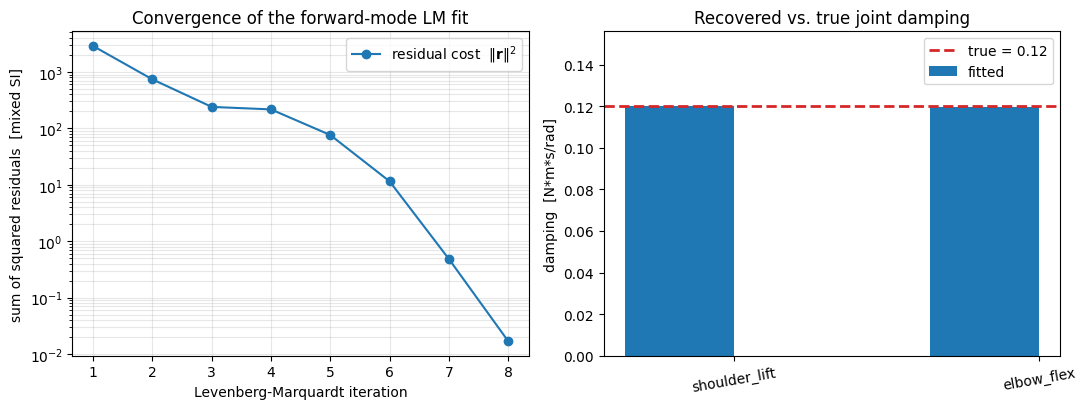

In [10]:
fig, (ax_cost, ax_par) = plt.subplots(1, 2, figsize=(11, 4.2))

# Left: cost convergence (log scale)
ax_cost.semilogy(
    range(1, len(history) + 1),
    history,
    "o-",
    color="C0",
    label="residual cost  $\\|\\mathbf{r}\\|^2$",
)
ax_cost.set_xlabel("Levenberg-Marquardt iteration")
ax_cost.set_ylabel("sum of squared residuals  [mixed SI]")
ax_cost.set_title("Convergence of the forward-mode LM fit")
ax_cost.grid(True, which="both", alpha=0.3)
ax_cost.legend()

# Right: recovered vs true damping
x = np.arange(len(TARGET_PARAMS))
ax_par.bar(
    x - 0.18, [fitted[p] for p in TARGET_PARAMS], width=0.36, color="C0", label="fitted"
)
ax_par.axhline(TRUE_DAMPING, color="C3", ls="--", lw=2, label=f"true = {TRUE_DAMPING}")
ax_par.set_xticks(x)
ax_par.set_xticklabels([p.split(".")[0] for p in TARGET_PARAMS], rotation=10)
ax_par.set_ylabel("damping  [N*m*s/rad]")
ax_par.set_title("Recovered vs. true joint damping")
ax_par.set_ylim(0, TRUE_DAMPING * 1.3)
ax_par.legend()

fig.tight_layout()
plt.show()

*Figure 1: (left) the residual cost falls monotonically by ~5 orders of magnitude
over eight LM iterations — the forward-mode Jacobian gives a clean descent
direction. (right) the fitted damping for both joints (blue bars) sits on the true
value (red dashed line) to better than $10^{-3}$; the bars are visually
indistinguishable from the line.*

### The payoff, in motion

Numbers are convincing; motion is visceral. The GIF below runs the same SO-101 from
the same off-balance pose twice: **left, uncalibrated** (`damping = 0.0`, the URDF
default) overshoots and oscillates; **right, calibrated** (`damping = 0.12`, what we
just identified) settles cleanly. This is the sim-to-real gap, closed by one
forward-mode fit.

![SO-101 uncalibrated vs calibrated, side by side](assets/sysid_before_after.gif)

*Figure 2: the SO-101 released from a folded, off-balance pose. Left
(uncalibrated, damping 0.0) keeps swinging; right (calibrated, damping 0.12)
damps out and settles. Same model, same release — only the identified parameter
differs.*

To quantify what the GIF shows, we simulate both arms from that release pose and
compare the shoulder-lift trajectory.

In [11]:
ARM_START = [
    0.8,
    -1.0,
    1.2,
    -0.6,
    0.5,
    0.6,
]  # the folded, off-balance pose from the GIF
SETTLE_T = 4.0


def settle_trajectory(damping):
    """Release the arm from ARM_START with the given damping; record [q, qd](t)."""
    r = robot.with_parameters({p: damping for p in TARGET_PARAMS})
    diagram, system = r.to_diagram(q0=ARM_START, qd0=[0.0] * NDOF, return_system=True)
    opts = SimulatorOptions(
        math_backend="jax",
        ode_solver_method="rk4",
        max_minor_step_size=0.005,
        save_time_series=True,
        buffer_length=2000,
        recorded_signals={"state": system.output_ports[0]},
    )
    res = jaxonomy.simulate(
        diagram, diagram.create_context(), (0.0, SETTLE_T), options=opts
    )
    return np.asarray(res.time), np.asarray(res.outputs["state"])


t_set, X_uncal = settle_trajectory(0.0)
_, X_cal = settle_trajectory(TRUE_DAMPING)

SHOULDER_LIFT_Q = 1  # qpos index of shoulder_lift
span_uncal = float(np.ptp(X_uncal[:, SHOULDER_LIFT_Q]))
span_cal_late = float(np.ptp(X_cal[len(X_cal) // 2 :, SHOULDER_LIFT_Q]))
print(f"shoulder_lift angle span (full window), uncalibrated : {span_uncal:.2f} rad")
print(f"shoulder_lift angle span (late half),   calibrated   : {span_cal_late:.2f} rad")

shoulder_lift angle span (full window), uncalibrated : 3.48 rad
shoulder_lift angle span (late half),   calibrated   : 0.57 rad


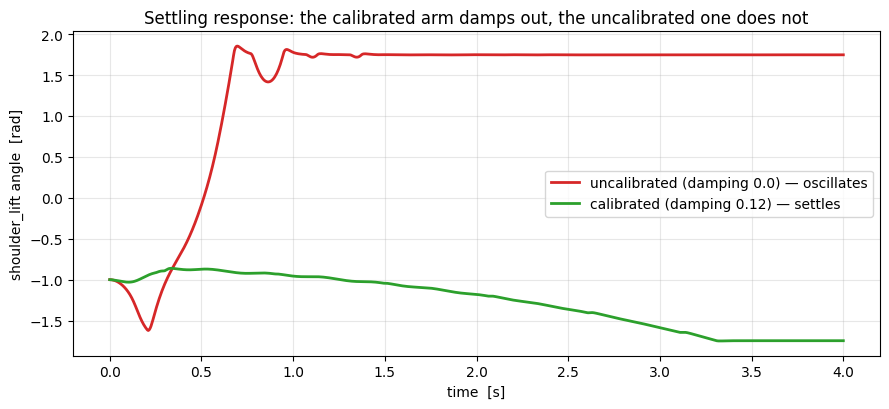

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(
    t_set,
    X_uncal[:, SHOULDER_LIFT_Q],
    color="C3",
    lw=2,
    label="uncalibrated (damping 0.0) — oscillates",
)
ax.plot(
    t_set,
    X_cal[:, SHOULDER_LIFT_Q],
    color="C2",
    lw=2,
    label="calibrated (damping 0.12) — settles",
)
ax.set_xlabel("time  [s]")
ax.set_ylabel("shoulder_lift angle  [rad]")
ax.set_title(
    "Settling response: the calibrated arm damps out, the uncalibrated one does not"
)
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

*Figure 3: shoulder-lift angle vs. time after release. The uncalibrated arm
(red) keeps swinging across a ~3.5 rad range; the calibrated arm (green) decays
toward its rest angle. The green curve is the dynamics the deployed controller
should be tuned against — the whole point of calibration.*

### Diagnostics

This is open-loop free dynamics — no actuator, no controller, no state machine —
so the saturation/phase diagnostics do not apply. The one diagnostic that *is*
meaningful is oscillation: a calibrated arm should oscillate **less** than an
uncalibrated one. We count zero crossings of the shoulder-lift velocity for both.

In [13]:
SHOULDER_LIFT_QD = NDOF + SHOULDER_LIFT_Q  # qd index of shoulder_lift

for label, X in (("uncalibrated", X_uncal), ("calibrated  ", X_cal)):
    rep = analyze_control_oscillation(
        X[:, SHOULDER_LIFT_QD],
        t_set,
        name=f"shoulder_lift velocity ({label.strip()})",
        detrend=False,
        warn=False,
    )
    print(f"{label}: {rep.crossings_per_second:.2f} velocity zero-crossings/s")

uncalibrated: 9.25 velocity zero-crossings/s
calibrated  : 6.00 velocity zero-crossings/s


The uncalibrated arm crosses zero noticeably more often than the calibrated one —
it keeps reversing direction as it oscillates, while the calibrated arm reverses
only as it settles. Both report a non-zero crossing rate (this is a swinging
pendulum decaying, not a controller, so some crossings are physical and expected);
the *comparison* is the signal, and it confirms calibration reduced the
oscillation. We pass `warn=False` precisely because there is no controller here to
mistune — the diagnostic's threshold is calibrated for actuated systems, so we read
the raw crossing counts rather than the pass/fail flag.

### Package the result and attest

A fit is not done until it is recorded. Jaxterity's `SysidResult` carries the
fitted parameters, residual statistics, the telemetry hash, and the recipe
name/version. Its `apply_to` binds the parameters to the robot **and** appends a
provenance record, so the calibrated robot's attestation handle reflects *how* it
was fitted (ADR-008/010). Two robots with identical parameters but different
recipe versions or telemetry get different handles — provenance is part of
identity.

In [14]:
result = SysidResult(
    fitted={p: jnp.asarray(v) for p, v in fitted.items()},
    residuals={"final_state_rms": float(np.sqrt(history[-1] / telemetry.size))},
    telemetry_hash="so101-demo-telemetry",
    recipe_name="forward_mode_lm_damping",
    recipe_version="1.0",
)

calibrated = result.apply_to(robot)  # returns a NEW robot; `robot` is unchanged

print("calibrated robot:")
print(f"  calibration state : {calibrated.calibration_state.value}")
print(
    f"  fitted damping    : "
    f"{ {p: round(float(calibrated.joint_map[p.split('.')[0]].damping), 5) for p in TARGET_PARAMS} }"
)
print(f"  provenance        : {calibrated.provenance}")
print(f"\n  attestation handle (calibrated)   : {calibrated.attestation_handle}")
print(f"  attestation handle (uncalibrated) : {robot.attestation_handle}")
assert calibrated.attestation_handle != robot.attestation_handle
assert robot.attestation_handle == handle_uncal  # the original is genuinely unchanged
print("\n  handles differ -> the calibration is recorded in the robot's identity.")

calibrated robot:
  calibration state : calibrated
  fitted damping    : {'shoulder_lift.damping': 0.12001, 'elbow_flex.damping': 0.11981}
  provenance        : (('forward_mode_lm_damping', '1.0', 'so101-demo-telemetry'),)

  attestation handle (calibrated)   : 8a6599cb1b1b2d2002d7e53d574c88d35f4cfc5e1236485980a8711cc359136e
  attestation handle (uncalibrated) : a792756aef095c50840d6063b50cef0d830b285bcf9e17513294546b1c60c263

  handles differ -> the calibration is recorded in the robot's identity.


The calibrated robot is a distinct, attested object: its state is `calibrated`, its
provenance names the recipe and telemetry, and its handle has changed — while the
original `robot` is byte-for-byte the one we loaded. That single calibrated `Robot`
is now ready to flow into a controller, a sim2real study, or a Jaxility
deployment, carrying its calibration provenance with it.

## 5. Floating base: a torque-free tumbling body

The SO-101 is fixed to a table. Drones, legged robots, and free-flying bodies are
not — their root link floats. Jaxterity now supports this with a single
`JointType.FLOATING` joint whose parent is `"world"` (ADR-018).

A free joint is subtle: it has **7** configuration coordinates `qpos` (3
translation + a unit quaternion) but only **6** velocities `qvel` (3 linear + 3
angular), so $n_q \neq n_v$. The configuration derivative is therefore *not* simply
$\dot{\mathbf{q}} = \dot q$: the orientation rate is the quaternion kinematic map

$$
\dot{\mathbf{Q}} = \tfrac{1}{2}\,\mathbf{Q} \otimes [0,\ \boldsymbol{\omega}_{\text{body}}],
\tag{3}
$$

where $\mathbf{Q}$ is the unit quaternion, $\boldsymbol{\omega}_{\text{body}}$ the
body-frame angular velocity, and $\otimes$ the Hamilton product. Because Jaxonomy
integrates a generic $\mathrm{d}\mathbf{x}/\mathrm{d}t$ with an ODE solver (not
MuJoCo's special quaternion integrator), Jaxterity's wrapper supplies this map
itself. The factor $\tfrac{1}{2}$ is exactly what keeps $\|\mathbf{Q}\| = 1$: the
derivative $\dot{\mathbf{Q}}$ is tangent to the unit sphere, so a good integrator
stays on it.

We build the classic demonstration of free-body rotation: the **Dzhanibekov /
tennis-racket effect**. A rigid body with three distinct principal moments of
inertia, spun about its *intermediate* axis, is unstable — it periodically flips
end-over-end even with zero applied torque. We give a plate with inertia
$\mathrm{diag}(0.1, 0.2, 0.3)\ \mathrm{kg\,m^2}$ a spin dominated by its
intermediate ($y$) axis and watch.

In [15]:
I_DIAG = (0.1, 0.2, 0.3)  # principal moments; the middle one (y) is the unstable axis


def free_body() -> Robot:
    """A single rigid plate on a FLOATING joint, in zero gravity."""
    free = Joint(
        name="root",
        joint_type=JointType.FLOATING,
        parent_link="world",
        child_link="plate",
        axis=FramedQuantity(Position(jnp.array([0.0, 0.0, 1.0])), Frame("world")),
        limits=JointLimits(lower=-1.0, upper=1.0, effort=1.0, velocity=1.0),
        origin=Transform.identity(Frame("world")),
        damping=jnp.asarray(0.0),
        friction=jnp.asarray(0.0),
    )
    plate = Link(
        name="plate",
        body_frame=Frame("plate"),
        mass=jnp.asarray(1.0),
        com=jnp.zeros(3),
        inertia=jnp.diag(jnp.asarray(I_DIAG)),
    )
    return Robot(links=(plate,), joints=(free,), name="dzhanibekov", gravity=0.0)


fb = free_body()
mjcf_fb = fb.to_mjcf()
import mujoco  # noqa: E402  (lazy: only needed to introspect the emitted MJCF)

model_fb = mujoco.MjModel.from_xml_string(mjcf_fb)
print(f"FLOATING joint -> <freejoint> emitted : {'<freejoint' in mjcf_fb}")
print(f"nq = {model_fb.nq} (3 translation + 4 quaternion), nv = {model_fb.nv} (3 + 3)")
print(f"identifiable parameters: {list(fb.parameters())}")
print("  (a free base exposes no joint dynamics -- only the body's inertials)")

FLOATING joint -> <freejoint> emitted : True
nq = 7 (3 translation + 4 quaternion), nv = 6 (3 + 3)
identifiable parameters: ['plate.mass', 'plate.com', 'plate.inertia']
  (a free base exposes no joint dynamics -- only the body's inertials)


The free joint emits a MuJoCo `<freejoint>`, the model gains a quaternion
($n_q = 7 \neq n_v = 6$), and — correctly — the free base contributes *no*
identifiable joint parameters (only the plate's mass/com/inertia). Now we simulate
a 6-second tumble and record the full state.

In [16]:
QD0_SPIN = jnp.array(
    [
        0.0,
        0.0,
        0.0,  # zero linear velocity
        0.1,
        3.0,
        0.05,
    ]
)  # spin mostly about the intermediate (y) axis
TUMBLE_T = 6.0

diagram_fb, system_fb = fb.to_diagram(qd0=QD0_SPIN, return_system=True)
opts_fb = SimulatorOptions(
    math_backend="jax",
    ode_solver_method="rk4",
    max_minor_step_size=0.002,
    save_time_series=True,
    buffer_length=4000,
    recorded_signals={"state": system_fb.output_ports[0]},
)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # silence any benign buffer-sizing notice
    res_fb = jaxonomy.simulate(
        diagram_fb, diagram_fb.create_context(), (0.0, TUMBLE_T), options=opts_fb
    )

t_fb = np.asarray(res_fb.time)
X_fb = np.asarray(res_fb.outputs["state"])
# state layout: q = [pos(3), quat(4)], qd = [v_lin(3), omega_body(3)]
quat = X_fb[:, 3:7]
omega = X_fb[:, 10:13]
print(
    f"recorded {X_fb.shape[0]} samples over {t_fb[-1]:.1f}s; state dim {X_fb.shape[1]}"
)

recorded 3002 samples over 6.0s; state dim 13


The visual payoff — a clearly asymmetric body spinning about its middle axis and
periodically flipping, all torque-free:

![Torque-free tennis-racket / Dzhanibekov flip](assets/dzhanibekov.gif)

*Figure 4: the Dzhanibekov effect. An asymmetric body (red = long x axis, green =
intermediate y axis, blue = short z axis) is spun about its green intermediate
axis in zero gravity and flips end-over-end at regular intervals, with no applied
torque.*

### Validation against theory: conservation

A torque-free rigid body must conserve **rotational kinetic energy**
$T = \tfrac{1}{2}\,\boldsymbol{\omega}^{\!\top}\mathbf{I}\,\boldsymbol{\omega}$ and
the **magnitude of angular momentum** $\|\mathbf{L}\| = \|\mathbf{I}\,\boldsymbol{\omega}\|$
(both are exact integrals of Euler's equations). The flips redistribute energy
*between* axes but the totals are invariant. And the integrator must keep the
quaternion on the unit sphere. These three checks together validate the
floating-base dynamics — there is no telemetry to fit here, only physics to
verify.

In [17]:
I = np.array(I_DIAG)
KE = 0.5 * np.sum(omega**2 * I, axis=1)  # rotational kinetic energy
L_mag = np.linalg.norm(omega * I, axis=1)  # |angular momentum| (body frame)
q_norm = np.linalg.norm(quat, axis=1)  # quaternion norm (should be 1)

ke_drift = abs(KE[-1] - KE[0]) / KE[0]
L_drift = abs(L_mag[-1] - L_mag[0]) / L_mag[0]
print(
    f"kinetic energy   : {KE[0]:.6f} -> {KE[-1]:.6f} J   (relative drift {ke_drift:.2e})"
)
print(
    f"|angular momentum|: {L_mag[0]:.6f} -> {L_mag[-1]:.6f}    (relative drift {L_drift:.2e})"
)
print(f"quaternion norm  : in [{q_norm.min():.9f}, {q_norm.max():.9f}]  (should be 1)")

kinetic energy   : 0.900875 -> 0.900875 J   (relative drift 2.29e-14)
|angular momentum|: 0.600271 -> 0.600271    (relative drift 1.17e-14)
quaternion norm  : in [1.000000000, 1.000000000]  (should be 1)


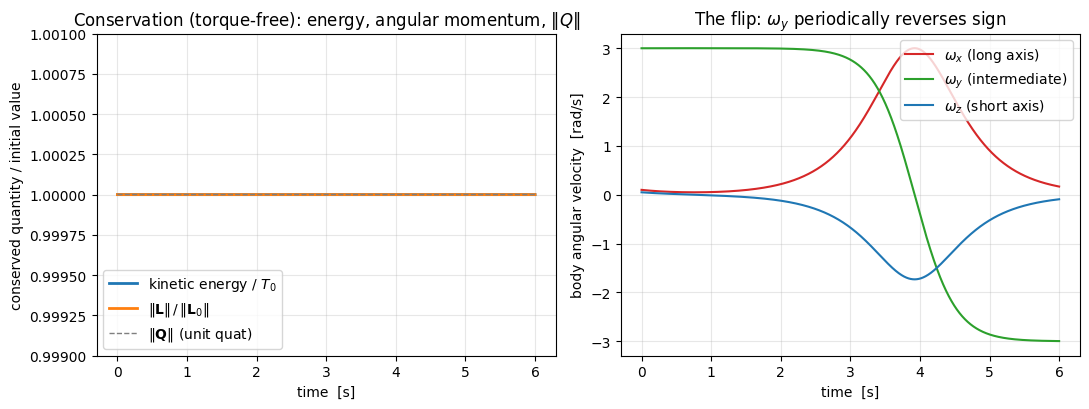

In [18]:
fig, (ax_cons, ax_omega) = plt.subplots(1, 2, figsize=(11, 4.2))

# Left: conserved quantities, normalised to their initial value
ax_cons.plot(t_fb, KE / KE[0], color="C0", lw=2, label="kinetic energy / $T_0$")
ax_cons.plot(
    t_fb,
    L_mag / L_mag[0],
    color="C1",
    lw=2,
    label=r"$\|\mathbf{L}\|\,/\,\|\mathbf{L}_0\|$",
)
ax_cons.plot(
    t_fb, q_norm, color="C7", lw=1, ls="--", label=r"$\|\mathbf{Q}\|$ (unit quat)"
)
ax_cons.set_xlabel("time  [s]")
ax_cons.set_ylabel("conserved quantity / initial value")
ax_cons.set_ylim(0.999, 1.001)
ax_cons.set_title("Conservation (torque-free): energy, angular momentum, $\\|Q\\|$")
ax_cons.grid(True, alpha=0.3)
ax_cons.legend(loc="lower left")

# Right: the flip itself -- omega about the intermediate (y) axis reverses sign
ax_omega.plot(t_fb, omega[:, 0], color="C3", lw=1.5, label=r"$\omega_x$ (long axis)")
ax_omega.plot(t_fb, omega[:, 1], color="C2", lw=1.5, label=r"$\omega_y$ (intermediate)")
ax_omega.plot(t_fb, omega[:, 2], color="C0", lw=1.5, label=r"$\omega_z$ (short axis)")
ax_omega.set_xlabel("time  [s]")
ax_omega.set_ylabel("body angular velocity  [rad/s]")
ax_omega.set_title("The flip: $\\omega_y$ periodically reverses sign")
ax_omega.grid(True, alpha=0.3)
ax_omega.legend(loc="upper right")

fig.tight_layout()
plt.show()

*Figure 5: (left) kinetic energy and angular-momentum magnitude stay flat to ~1
part in $10^{13}$, and the quaternion norm stays at 1 — the floating-base
integration conserves what physics says it must. (right) the Dzhanibekov flip in
the data: $\omega_y$ (green, the intermediate axis) reverses sign periodically
while energy sloshes between the long ($x$) and short ($z$) axes. This is the
tennis-racket effect, reproduced from first-principles free-body dynamics.*

The conserved quantities are flat to machine precision and the quaternion never
leaves the unit sphere — strong evidence the free-joint kinematics and the
$\tfrac{1}{2}\mathbf{Q}\otimes\boldsymbol{\omega}$ map are correct.

## Failure modes

Forward-mode sysid is powerful but not magic. Concretely, it degrades or fails
here:

- **Active joint-limit impacts.** If the excitation drives a joint *into* its
  limit, MJX's constraint becomes active and the dynamics develop a kink. The
  gradient through that kink is ill-defined for forward-mode, reverse-mode, and
  finite differences alike (they disagree). Keep $|\mathbf{q}|$ inside the limits
  — our $\dot q_0 = 0.1\ \mathrm{rad/s}$ over $0.3\ \mathrm{s}$ does (peak angle
  $\approx 0.9$ rad vs. a $\approx 1.7$ rad limit).
- **Weak excitation.** If a parameter barely moves the trajectory over the sample
  window, its column of $\mathbf{J}$ is tiny and $\mathbf{J}^{\!\top}\mathbf{J}$ is
  near-singular; LM will stall or wander. The forward-mode sensitivities in §3 are
  a cheap pre-check: both were $\gtrsim 10^4$, so the problem is well-conditioned.
  Damping near zero with little motion is the classic weak-excitation trap.
- **Many parameters.** Forward-mode costs one tangent sweep *per parameter*.
  Identifying a handful of damping/friction terms is ideal; identifying dozens of
  inertial parameters at once would be expensive — reach for reverse-mode there,
  but only on constraint-free problems (`enable_autodiff=True`, a stiff solver),
  since reverse-mode still cannot cross a `while_loop`.
- **com / inertia.** Those parameters live in the MJCF *structure*, not the
  runtime model arrays, so they are not yet runtime-differentiable
  (`parameter_jacobian` raises a typed error if you ask). They are fittable by
  structural rebuild via `with_parameters`; runtime threading is on the roadmap.
- **Floating base + dopri5 reverse-mode.** The free-joint quaternion map composes
  with forward-mode and fixed-step solvers cleanly; reverse-mode through an
  adaptive `dopri5` rollout of a floating base is not a validated path. Use RK4 for
  free-body work, as we did.
- **One floating base.** Exactly one `FLOATING` joint is supported; two raise a
  typed error.

## Exercises

1. **(Code, easy.)** Add a third target joint — `wrist_flex.damping` — to
   `TARGET_PARAMS`, plant the same true damping in `true_robot`, and re-run §2–4.
   Does the fit still recover all three? Watch the per-iteration cost: does adding
   a parameter slow convergence?

2. **(Code, medium.)** Identify two *different* true values, e.g.
   `shoulder_lift = 0.20` and `elbow_flex = 0.05`, by changing `with_parameters`
   to a per-joint dict. Confirm the fit recovers each independently. Then corrupt
   the telemetry with Gaussian noise (`telemetry += 1e-3 * np.random.randn(*telemetry.shape)`,
   seeded) and see how the recovered values and final RMS residual degrade.

3. **(Conceptual.)** §3 showed reverse-mode `jax.grad` raising on the SO-101.
   Explain in two sentences *why* forward-mode succeeds where reverse-mode fails on
   the same `while_loop`, in terms of what each mode needs to know at trace time.
   Then: for a 200-parameter inertial fit on a *constraint-free* robot, which mode
   would you choose, and why?

4. **(Open-ended.)** The §5 free body conserves energy and angular momentum to
   $10^{-13}$ with fixed-step RK4. Sweep `max_minor_step_size` from 0.001 to 0.02
   and `ode_solver_method` between `"rk4"` and an adaptive method, and plot the
   conservation drift vs. step size. At what step size does the quaternion norm
   start to wander, and how does that compare to the energy drift? What does that
   tell you about which invariant is the more sensitive integrator diagnostic?

5. **(Open-ended.)** Design a calibration trajectory for the *real* SO-101 that
   maximises the forward-mode sensitivity to `elbow_flex.damping` while keeping
   every joint within limits. (Hint: damping couples to velocity, so excite the
   joint, do not just displace it — but excite it without slamming a limit.) How
   would you turn the §3 sensitivity read-out into an objective for trajectory
   design?

## Key takeaways

- **One model, end to end.** A real URDF becomes a `Robot`, which lowers to a
  differentiable MJX `Diagram`, gets calibrated against telemetry, and emerges as a
  single attested object ready for deployment — no sim/deploy model drift (ADR-004).
- **Forward-mode autodiff is the enabler for real arms.** Reverse-mode `jax.grad`
  cannot cross MJX's constraint-solver `while_loop` (we watched it raise);
  forward-mode carries tangents through it cleanly, with modest memory (ADR-017).
- **We recovered ground truth.** Joint damping of $0.12$ on a 6-DOF arm was
  identified to within a few $\times 10^{-4}$ by forward-mode Levenberg–Marquardt,
  through a constraint solver reverse-mode could not differentiate.
- **Calibration is attested.** `SysidResult.apply_to` binds the fit *and* records
  recipe/telemetry provenance into the robot's BLAKE3 attestation handle (ADR-008).
- **Floating-base dynamics are correct.** A free joint's quaternion map
  ($\tfrac12\mathbf{Q}\otimes\boldsymbol{\omega}$) reproduces the Dzhanibekov flip
  with energy and angular momentum conserved to machine precision (ADR-018).
- **Know the limits.** Active impacts are non-smooth for *any* method; com/inertia
  are not yet runtime-differentiable; use RK4, not reverse-mode dopri5, for
  floating bodies.

## Next steps

- **Sysid recipes.** `parameter_jacobian` is the primitive; packaged
  `actuator` / `inertial` / `full_body` recipes that return a `SysidResult` from a
  telemetry table are next.
- **Actuation.** `Robot.build_system(actuation=True)` exposes a joint-torque input
  port — wire a controller around the calibrated arm and close the loop.
- **More floating-base robots.** With ADR-018 in place, quadrotors and legged
  robots become reachable once rotor/contact models land (see `AGENTS/LIBRARIES.md`).
- **Deployment.** A calibrated, attested `Robot` is the input to Jaxility,
  which emits a self-contained C project plus a signed attestation manifest.

## References

1. V. V. Beletsky, *Dzhanibekov effect / tennis-racket theorem* — the instability
   of rotation about the intermediate principal axis of a torque-free rigid body
   (Euler's equations).
2. K. Levenberg (1944) and D. Marquardt (1963), the damped Gauss–Newton method
   used in §4.
3. MuJoCo / MJX — Todorov, Erez, Tassa, *MuJoCo: A physics engine for model-based
   control* (IROS 2012); MJX is its JAX rewrite.
4. Jaxterity `AGENTS/DECISIONS.md`, ADR-016 (MJX backend), ADR-017 (forward-mode
   sysid), ADR-018 (floating base), ADR-008 (attestation), ADR-004 (single source
   of truth).
5. SO-101 model: TheRobotStudio/SO-ARM100, `Simulation/SO101`, Apache-2.0.